## Loading KDEF dataset

This notebook has the necessary code to load and split your KDEF dataset. The training and test splits are already predefined.

In [6]:
#Import all necessary libraries
from pathlib import Path
import pandas as pd
import pickle
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import dlib
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,f1_score,
                             classification_report,confusion_matrix,ConfusionMatrixDisplay)


In [7]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
    
}

POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}


In [8]:
records = []

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    acquisition = stem[0]   # A or B
    subject = stem[1:4]     # F01, M12, ...
    found = False

    for emotion_code in EMOTIONS:

        if stem[4:].startswith(emotion_code):

            pose_code = stem[4+len(emotion_code):]

            if pose_code not in POSES:
                continue

            records.append({
                "path": str(img_path),
                "acquisition": acquisition,
                "subject": subject,
                "emotion": EMOTIONS[emotion_code],
                "pose": POSES[pose_code],
            })


            found = True
            break

    if not found:
        print("Skipping:", stem)


Skipping: AF31V
Skipping: AM31H


The KDEF dataset contains facial images representing seven emotion categories:

- afraid      
- angry       
- disgust     
- happy       
- neutral     
- sad         
- surprise    

Only frontal-pose images are selected for this experiment. To avoid data leakage, images belonging to the same subject are assigned exclusively to either the training set or the test set.

In [9]:
df = pd.DataFrame(records)

print(df["emotion"].value_counts())
print()
print(df["subject"].nunique())
print(sorted(df.emotion.unique()))
print(df.pose.value_counts())


emotion
afraid      700
angry       700
disgust     700
happy       700
neutral     700
sad         699
surprise    699
Name: count, dtype: int64

70
['afraid', 'angry', 'disgust', 'happy', 'neutral', 'sad', 'surprise']
pose
full_left     980
full_right    980
straight      980
half_left     979
half_right    979
Name: count, dtype: int64


In [10]:
with open("auxFiles/kdef_subject_split.pkl", "rb") as f:
    split_data = pickle.load(f)

train_subjects = split_data["train_subjects"]
test_subjects = split_data["test_subjects"]

print(f"Train subjects: {len(train_subjects)}")
print(f"Test subjects : {len(test_subjects)}")


# Splitting the datasets between front facing images and for the train/test datasets
train_df = df[
    (df["subject"].isin(train_subjects))
    & (df["pose"] == "straight")
]

test_df = df[
    (df["subject"].isin(test_subjects))
    & (df["pose"] == "straight")
]

Train subjects: 56
Test subjects : 14


The split contains 56 training subjects and 14 test subjects. Sessions A and B of the same person stay in the same split. With all frontal images processed successfully, this gives 784 training images and 196 test images.

In [11]:
print("Train images:", len(train_df))
print("Test images :", len(test_df))

Train images: 784
Test images : 196


Subject: F30


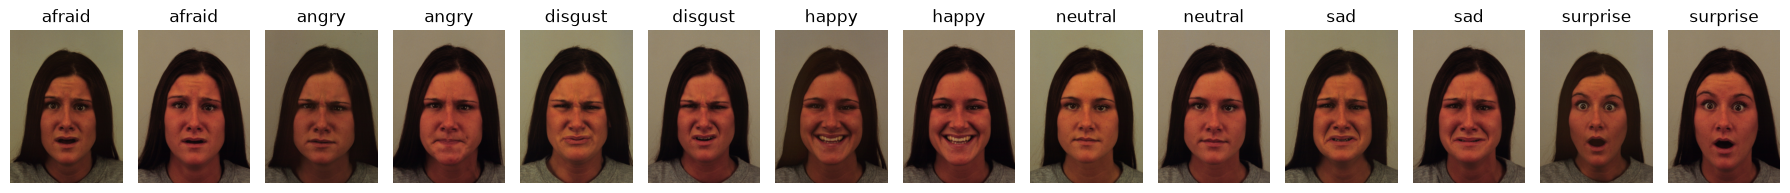

Subject: M15


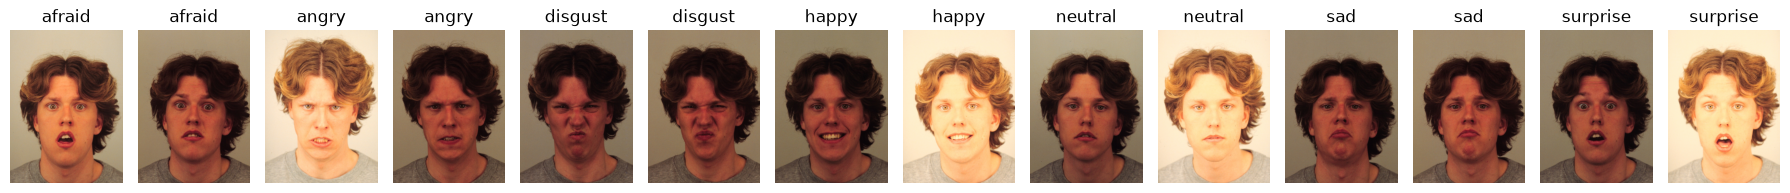

In [12]:
from src.utils_display import show_random_subject_emotions
show_random_subject_emotions(train_df)
show_random_subject_emotions(test_df)

The KDEF images are preprocessed to obtain a consistent representation suitable for feature extraction.

- The preprocessing pipeline consists of:

- Loading the original image.

- Converting the image to grayscale.

- Detecting the face using an OpenCV Haar cascade classifier.

- Expanding the detected face bounding box by a margin of 20%.

- Cropping the face region.

- Resizing the cropped face to 48 × 48 pixels.

- Normalizing pixel values to the range [0, 1].

The resulting images have dimensions of 48 × 48 pixels and are stored with their corresponding emotion labels.

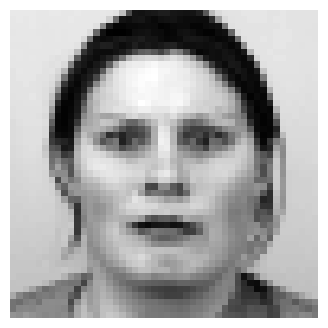

In [13]:
from src.preprocess import preprocess_kdef_image

img = preprocess_kdef_image(
train_df.iloc[0]["path"]
)

import matplotlib.pyplot as plt

def show_preprocessing(image_path):
    processed = preprocess_kdef_image(image_path)

    plt.figure(figsize=(4,4))
    plt.imshow(processed, cmap="gray")
    plt.axis("off")
    plt.show()

show_preprocessing(
    test_df.iloc[56]["path"]
)

The next part of the code iterates over all the images in the dataset and stores them in np arrays for easy processing

In [14]:
def preprocess_split(frame):
    images, labels, subjects, paths = [], [], [], []
    for _, row in frame.iterrows():
        try:
            image = preprocess_kdef_image(row["path"])
        except Exception as error:
            # Stop rather than silently change the dataset and reported results.
            raise RuntimeError(f"Could not preprocess {row['path']}") from error
        images.append(image)
        labels.append(row["emotion"])
        subjects.append(str(row["subject"]))
        paths.append(str(row["path"]))
    return (np.asarray(images), np.asarray(labels),
            np.asarray(subjects), np.asarray(paths))

(X_train_kdef, y_train_kdef, train_subject_ids,
 train_paths) = preprocess_split(train_df)
(X_test_kdef, y_test_kdef, test_subject_ids,
 test_paths) = preprocess_split(test_df)

assert set(train_subject_ids).isdisjoint(set(test_subject_ids))
assert len(X_train_kdef) == len(y_train_kdef) == len(train_subject_ids) == len(train_paths)
assert len(X_test_kdef) == len(y_test_kdef) == len(test_subject_ids) == len(test_paths)

data = {
    "X_train_kdef": X_train_kdef,
    "y_train_kdef": y_train_kdef,
    "X_test_kdef": X_test_kdef,
    "y_test_kdef": y_test_kdef,
    "train_subject_ids": train_subject_ids,
    "test_subject_ids": test_subject_ids,
    "train_paths": train_paths,
    "test_paths": test_paths,
}
with open("data/kdef_preprocessed.pkl", "wb") as file:
    pickle.dump(data, file)
print("Saved images, labels, subject IDs, and paths in the same order.")
print("Train:", len(X_train_kdef), "images;", len(np.unique(train_subject_ids)), "subjects")
print("Test:", len(X_test_kdef), "images;", len(np.unique(test_subject_ids)), "subjects")

Saved images, labels, subject IDs, and paths in the same order.
Train: 784 images; 56 subjects
Test: 196 images; 14 subjects


Now let's see a few of our preprocessed images. Note that both sessions A and B now are stored. The data array contains first all the A session images, and afterwards all the B session images

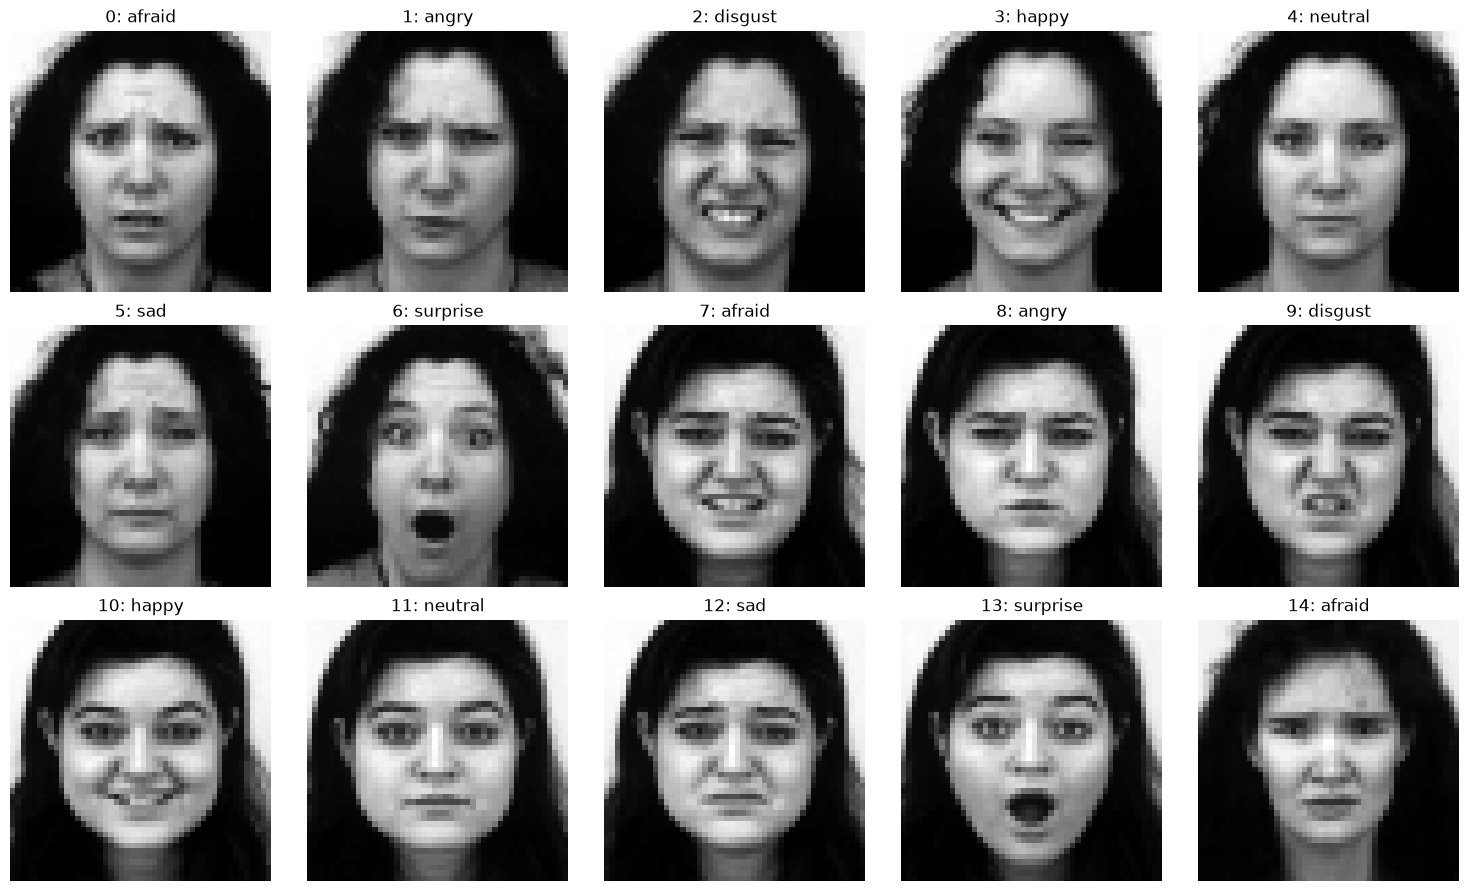

In [15]:
def show_samples(X, y, start_idx, end_idx):
    """
    Display images from start_idx to end_idx (exclusive)
    together with their emotion labels.
    """

    n = end_idx - start_idx
    cols = 5
    rows = math.ceil(n / cols)

    plt.figure(figsize=(3 * cols, 3 * rows))

    for i, idx in enumerate(range(start_idx, end_idx)):
        plt.subplot(rows, cols, i + 1)

        img = X[idx]

        # grayscale or RGB
        if img.ndim == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)

        plt.title(f"{idx}: {y[idx]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# This is an example of the images of the session A
show_samples(X_train_kdef, y_train_kdef, start_idx=0, end_idx=15)

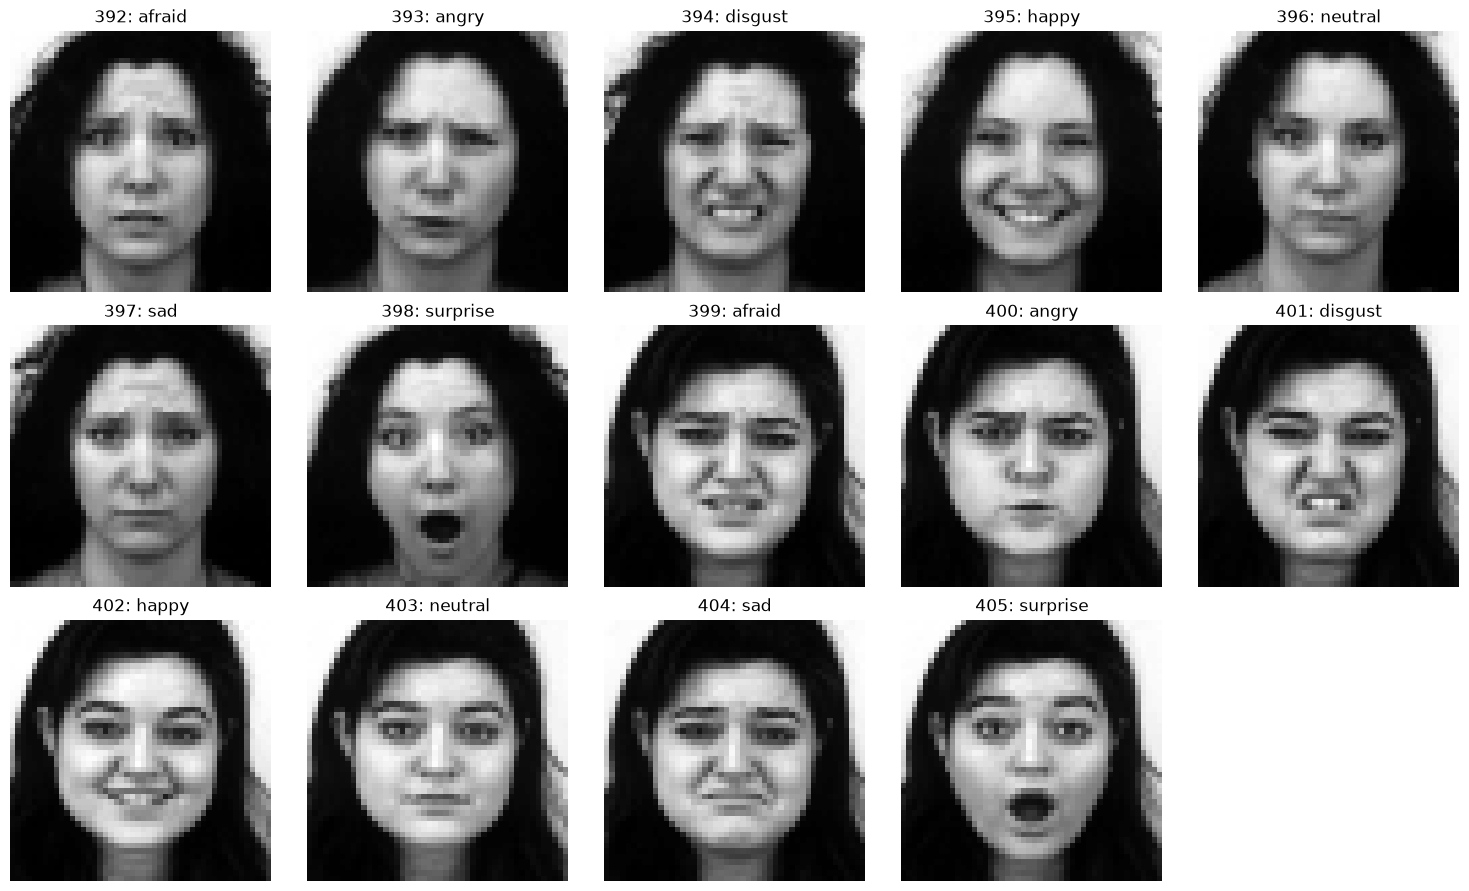

In [16]:
# This is an example of the images of the session B
show_samples(X_train_kdef, y_train_kdef, start_idx=392, end_idx=406)

# Feature Extraction

**HOG** - Histogram of Oriented Gradients

HOG is used to represent facial structure through local intensity gradients and edge orientations.

The HOG configuration uses:

- Orientations: 9

- Pixels per cell: 8 × 8

- Cells per block: 2 × 2

- Block normalization: L2-Hys

For a 48 × 48 image, this configuration produces a feature vector containing 900 values.

HOG features represent local facial structures such as edges around the eyes, eyebrows, nose, and mouth. These features are then supplied to the classification algorithms.

In [17]:
def prepare_gray_image(image):

    # Convert input image to numpy array
    image = np.squeeze(np.asarray(image))

    # If image has 3 dimensions then convert RGB to grayscale
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # If image pixel values are in [0,1] then normalize it to [0,255]
    if image.max() <= 1.0:
        image = image * 255.0

    # Clip pixel value to 8-bit range and convert to uint8
    return np.clip(image, 0, 255).astype(np.uint8)


# Apply HOG 
def extract_hog_kdef(images):
    features = []

    for image in images:
        image = prepare_gray_image(image)

        feature = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        features.append(feature)

    # Convert the list of feature vectors into float32 Numpy array
    return np.asarray(features, dtype=np.float32)


X_train_hog = extract_hog_kdef(X_train_kdef)
X_test_hog = extract_hog_kdef(X_test_kdef)

print("HOG training:", X_train_hog.shape)
print("HOG testing:", X_test_hog.shape)

HOG training: (784, 900)
HOG testing: (196, 900)


**The following configurations are evaluated:**

- Support Vector Machine (SVM) using HOG features.

- Random Forest using HOG features.

- Logistic Regression using HOG features.

- SVM using facial landmarks.

- SVM using combined HOG and landmark features.

- Random Forest using combined HOG and landmark features.


**The models are evaluated using the following metrics:**

- Accuracy: Proportion of correctly classified images.

- Balanced accuracy: Average recall across emotion classes.

- Macro F1-score: Unweighted average of the F1-scores across classes.

Macro F1-score is particularly useful when evaluating emotion datasets with unequal class distributions because each class contributes equally to the final score.

**SVM + HOG**

Accuracy: 0.5969387755102041
Balanced accuracy: 0.5969387755102041
Macro F1: 0.6040986592949126

Classification report:

              precision    recall  f1-score   support

      afraid       0.35      0.39      0.37        28
       angry       0.41      0.43      0.42        28
     disgust       0.85      0.61      0.71        28
       happy       0.96      0.82      0.88        28
     neutral       0.74      0.61      0.67        28
         sad       0.48      0.54      0.51        28
    surprise       0.58      0.79      0.67        28

    accuracy                           0.60       196
   macro avg       0.63      0.60      0.60       196
weighted avg       0.63      0.60      0.60       196



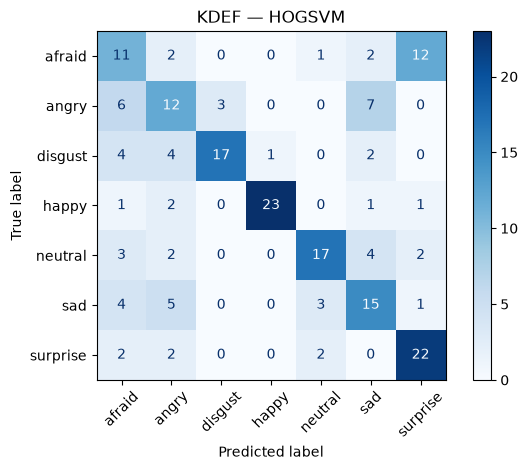

In [18]:
svm_hog = make_pipeline(
    StandardScaler(),
    SVC(C=10, kernel="rbf")
)

svm_hog.fit(X_train_hog, y_train_kdef)

y_pred_svm_hog = svm_hog.predict(X_test_hog)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_svm_hog))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_svm_hog))
print("Macro F1:", f1_score(y_test_kdef, y_pred_svm_hog, average="macro"))

print("\nClassification report:\n")
print(classification_report(y_test_kdef, y_pred_svm_hog))

labels = [
    "afraid", "angry", "disgust", "happy",
    "neutral", "sad", "surprise"
]

cm = confusion_matrix(y_test_kdef, y_pred_svm_hog, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.xticks(rotation=45)
plt.title("KDEF — HOGSVM")
plt.tight_layout()
plt.show()



**Random Forest + HOG**

Accuracy: 0.6275510204081632
Balanced accuracy: 0.6275510204081634
Macro F1: 0.6134117298348795

Classification report:

              precision    recall  f1-score   support

      afraid       0.44      0.25      0.32        28
       angry       0.84      0.57      0.68        28
     disgust       0.73      0.68      0.70        28
       happy       0.70      0.93      0.80        28
     neutral       0.60      0.75      0.67        28
         sad       0.67      0.43      0.52        28
    surprise       0.49      0.79      0.60        28

    accuracy                           0.63       196
   macro avg       0.64      0.63      0.61       196
weighted avg       0.64      0.63      0.61       196



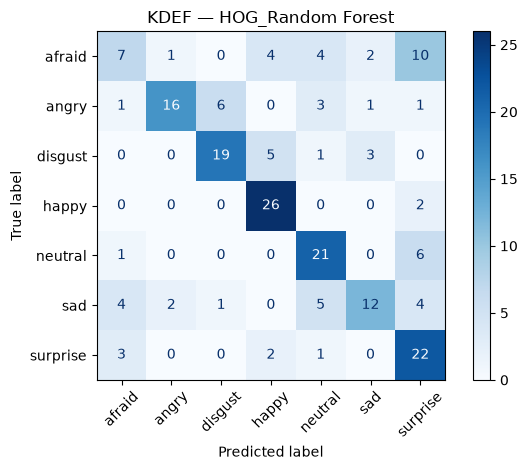

In [19]:
rf_hog = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=300,       # Number of trees
        max_depth=11,           # Allow trees to grow fully
        max_features='sqrt',   # Use sqrt(features) for splitting
        random_state=42,
        n_jobs=-1,             # Use all available CPU cores 
        #class_weight= "balanced", #class_weights,
        criterion="entropy",)
)

rf_hog.fit(X_train_hog, y_train_kdef)

y_pred_rf_hog = rf_hog.predict(X_test_hog)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_rf_hog))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_rf_hog))
print("Macro F1:", f1_score(y_test_kdef, y_pred_rf_hog, average="macro"))

print("\nClassification report:\n")
print(classification_report(y_test_kdef, y_pred_rf_hog))

labels = [
    "afraid", "angry", "disgust", "happy",
    "neutral", "sad", "surprise"
]

cm = confusion_matrix(y_test_kdef, y_pred_rf_hog, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.xticks(rotation=45)
plt.title("KDEF — HOG_Random Forest")
plt.tight_layout()
plt.show()

**Logistic Regression + HOG**

Accuracy: 0.5561224489795918
Balanced accuracy: 0.5561224489795918
Macro F1: 0.5640093445615151

Classification report:

              precision    recall  f1-score   support

      afraid       0.34      0.54      0.42        28
       angry       0.58      0.39      0.47        28
     disgust       0.79      0.54      0.64        28
       happy       0.91      0.75      0.82        28
     neutral       0.62      0.64      0.63        28
         sad       0.42      0.39      0.41        28
    surprise       0.50      0.64      0.56        28

    accuracy                           0.56       196
   macro avg       0.60      0.56      0.56       196
weighted avg       0.60      0.56      0.56       196



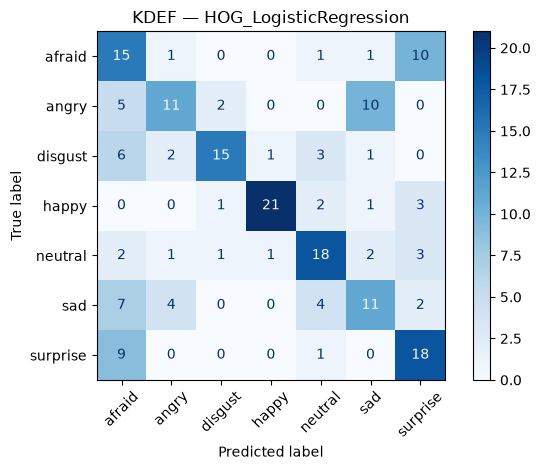

In [20]:
lg_hog = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

lg_hog.fit(X_train_hog, y_train_kdef)

y_pred_lg_hog = lg_hog.predict(X_test_hog)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_lg_hog))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_lg_hog))
print("Macro F1:", f1_score(y_test_kdef, y_pred_lg_hog, average="macro"))

print("\nClassification report:\n")
print(classification_report(y_test_kdef, y_pred_lg_hog))

labels = [
    "afraid", "angry", "disgust", "happy",
    "neutral", "sad", "surprise"
]

cm = confusion_matrix(y_test_kdef, y_pred_lg_hog, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.xticks(rotation=45)
plt.title("KDEF — HOG_LogisticRegression")
plt.tight_layout()
plt.show()

Facial landmark features are also investigated as an alternative representation. These features describe facial geometry using detected landmark positions.

The landmark-based approach is compared with HOG-based features to determine whether geometric information improves emotion classification.

In [21]:
landmDet = dlib.shape_predictor(
    "faceAndLandmarkModels/shape_predictor_68_face_landmarks_GTX.dat"
)


def extract_landmarks_kdef(images):
    all_landmarks = []

    for image in images:
        image = prepare_gray_image(image)

        height, width = image.shape

        face_rect = dlib.rectangle(
            left=1,
            top=1,
            right=width - 1,
            bottom=height - 1
        )

        landmarks = landmDet(image, face_rect)

        coords = np.array([
            [p.x, p.y] for p in landmarks.parts()
        ], dtype=np.float32)

        # Center the landmarks
        coords[:, 0] -= 0.5 * (width - 2)
        coords[:, 1] -= 0.5 * (height - 2)

        # Normalize the coordinates
        coords[:, 0] /= (width - 2)
        coords[:, 1] /= (height - 2)

        coords -= coords.mean(axis=0, keepdims=True)

        scale = np.max(np.abs(coords), axis=0, keepdims=True)
        coords /= np.maximum(scale, 1e-8)

        all_landmarks.append(coords.flatten())

    return np.stack(all_landmarks)


X_train_landmarks = extract_landmarks_kdef(X_train_kdef)
X_test_landmarks = extract_landmarks_kdef(X_test_kdef)

print("Landmarks training:", X_train_landmarks.shape)
print("Landmarks testing:", X_test_landmarks.shape)

Landmarks training: (784, 136)
Landmarks testing: (196, 136)


**SVM + Landmarks**

Accuracy: 0.3010204081632653
Balanced accuracy: 0.3010204081632653
Macro F1: 0.291953528915118

Classification report:

              precision    recall  f1-score   support

      afraid       0.25      0.36      0.29        28
       angry       0.32      0.25      0.28        28
     disgust       0.42      0.29      0.34        28
       happy       0.53      0.71      0.61        28
     neutral       0.09      0.07      0.08        28
         sad       0.10      0.11      0.10        28
    surprise       0.36      0.32      0.34        28

    accuracy                           0.30       196
   macro avg       0.30      0.30      0.29       196
weighted avg       0.30      0.30      0.29       196



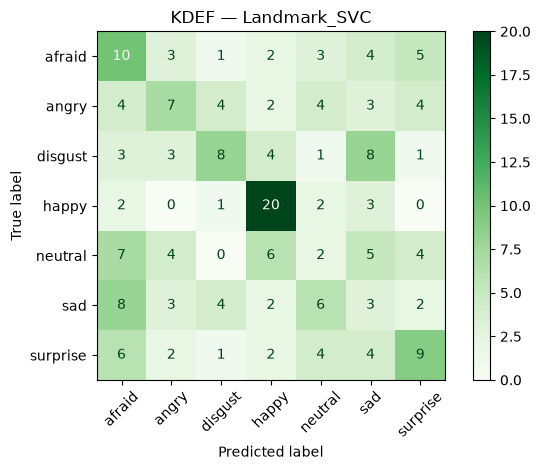

In [22]:
svm_landmarks = make_pipeline(
    StandardScaler(),
    SVC(C=10, kernel="rbf", random_state=42)
)

svm_landmarks.fit(X_train_landmarks, y_train_kdef)

y_pred_lm = svm_landmarks.predict(X_test_landmarks)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_lm))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_lm))
print("Macro F1:", f1_score(y_test_kdef, y_pred_lm, average="macro"))
print("\nClassification report:\n")
print(classification_report(y_test_kdef, y_pred_lm))

cm = confusion_matrix(y_test_kdef, y_pred_lm, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Greens", values_format="d")

plt.xticks(rotation=45)
plt.title("KDEF — Landmark_SVC")
plt.tight_layout()
plt.show()



**HOG + landmarks**

A combined representation using HOG features and facial landmarks is evaluated to investigate whether combining local appearance information with facial geometry improves classification performance.

In [23]:
X_train_combined = np.concatenate(
    [X_train_hog, X_train_landmarks], axis=1
)

X_test_combined = np.concatenate(
    [X_test_hog, X_test_landmarks], axis=1
)

print("Combined training:", X_train_combined.shape)
print("Combined testing:", X_test_combined.shape)

Combined training: (784, 1036)
Combined testing: (196, 1036)


**SVC + HOG + Landmarks**

Accuracy: 0.576530612244898
Balanced accuracy: 0.576530612244898
Macro F1: 0.5768586875888104

Classification report:

              precision    recall  f1-score   support

      afraid       0.42      0.39      0.41        28
       angry       0.39      0.39      0.39        28
     disgust       0.76      0.57      0.65        28
       happy       0.85      0.82      0.84        28
     neutral       0.60      0.54      0.57        28
         sad       0.44      0.54      0.48        28
    surprise       0.63      0.79      0.70        28

    accuracy                           0.58       196
   macro avg       0.59      0.58      0.58       196
weighted avg       0.59      0.58      0.58       196



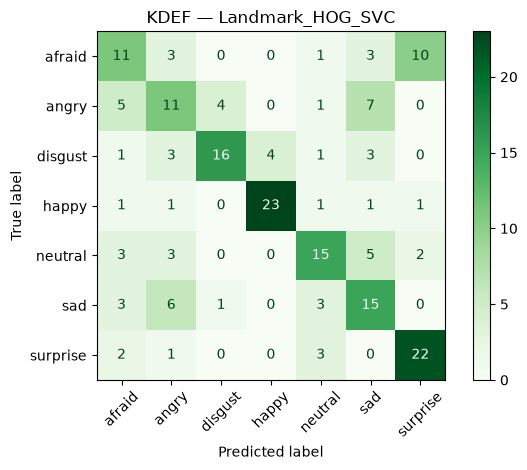

In [24]:
svm_combined = make_pipeline(
    StandardScaler(),
    SVC(C=10, kernel="rbf")
)

svm_combined.fit(X_train_combined, y_train_kdef)
y_pred_combined = svm_combined.predict(X_test_combined)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_combined))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_combined))
print("Macro F1:", f1_score(y_test_kdef, y_pred_combined, average="macro"))

print("\nClassification report:\n")
print(classification_report(y_test_kdef, y_pred_combined))

cm = confusion_matrix(y_test_kdef, y_pred_combined, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Greens", values_format="d")

plt.xticks(rotation=45)
plt.title("KDEF — Landmark_HOG_SVC")
plt.tight_layout()
plt.show()


**RF + HOG + Landmarks**

Accuracy: 0.6275510204081632
Balanced accuracy: 0.6275510204081634
Macro F1: 0.6129096724860725
              precision    recall  f1-score   support

      afraid       0.43      0.32      0.37        28
       angry       0.88      0.54      0.67        28
     disgust       0.70      0.75      0.72        28
       happy       0.76      0.93      0.84        28
     neutral       0.55      0.75      0.64        28
         sad       0.64      0.32      0.43        28
    surprise       0.52      0.79      0.63        28

    accuracy                           0.63       196
   macro avg       0.64      0.63      0.61       196
weighted avg       0.64      0.63      0.61       196



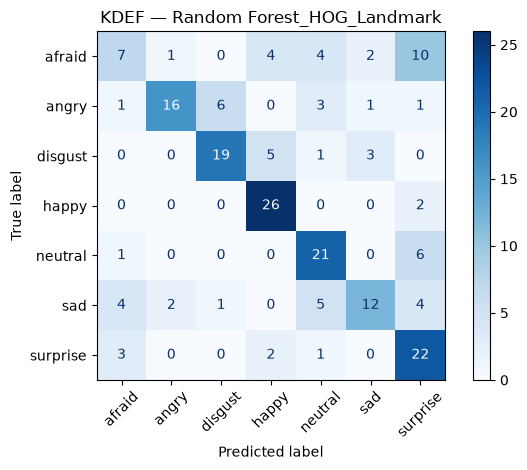

In [25]:
rf_combined = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=300,       # Number of trees
            max_depth=11,           # Allow trees to grow fully
            max_features='sqrt',   # Use sqrt(features) for splitting
            random_state=42,
            n_jobs=-1,             # Use all available CPU cores 
            #class_weight= "balanced", #class_weights,
            criterion="entropy")
)

rf_combined.fit(X_train_combined, y_train_kdef)
y_pred_rf_combined = rf_combined.predict(X_test_combined)

print("Accuracy:", accuracy_score(y_test_kdef, y_pred_rf_combined))
print("Balanced accuracy:", balanced_accuracy_score(y_test_kdef, y_pred_rf_combined))
print("Macro F1:", f1_score(y_test_kdef, y_pred_rf_combined, average="macro"))

print(classification_report(y_test_kdef, y_pred_rf_combined, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test_kdef,
    y_pred_rf_hog,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("KDEF — Random Forest_HOG_Landmark")
plt.tight_layout()
plt.show()

In [26]:
# Add each model and its corresponding test predictions
models = {
    "SVM (HOG)": (svm_hog, y_test_kdef, y_pred_svm_hog),
    "Logistic Regression (HOG)": (lg_hog, y_test_kdef, y_pred_lg_hog),
    "Random Forest (HOG)": (rf_hog, y_test_kdef, y_pred_rf_hog),
    "SVM (Landmarks)": (svm_landmarks, y_test_kdef, y_pred_lm),
    "SVM (HOG + Landmarks)": (svm_combined, y_test_kdef, y_pred_combined),
    "Random Forest (HOG + Landmarks)": (rf_combined, y_test_kdef, y_pred_rf_combined)
}

results = []

for model_name, (model, y_true, y_pred) in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred, average="macro")
    })

results_df = pd.DataFrame(results)

# Sort by accuracy
results_df = results_df.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Balanced Accuracy,F1 Score
0,Random Forest (HOG),0.6276,0.6276,0.6134
1,Random Forest (HOG + Landmarks),0.6276,0.6276,0.6129
2,SVM (HOG),0.5969,0.5969,0.6041
3,SVM (HOG + Landmarks),0.5765,0.5765,0.5769
4,Logistic Regression (HOG),0.5561,0.5561,0.5640
5,SVM (Landmarks),0.3010,0.3010,0.2920


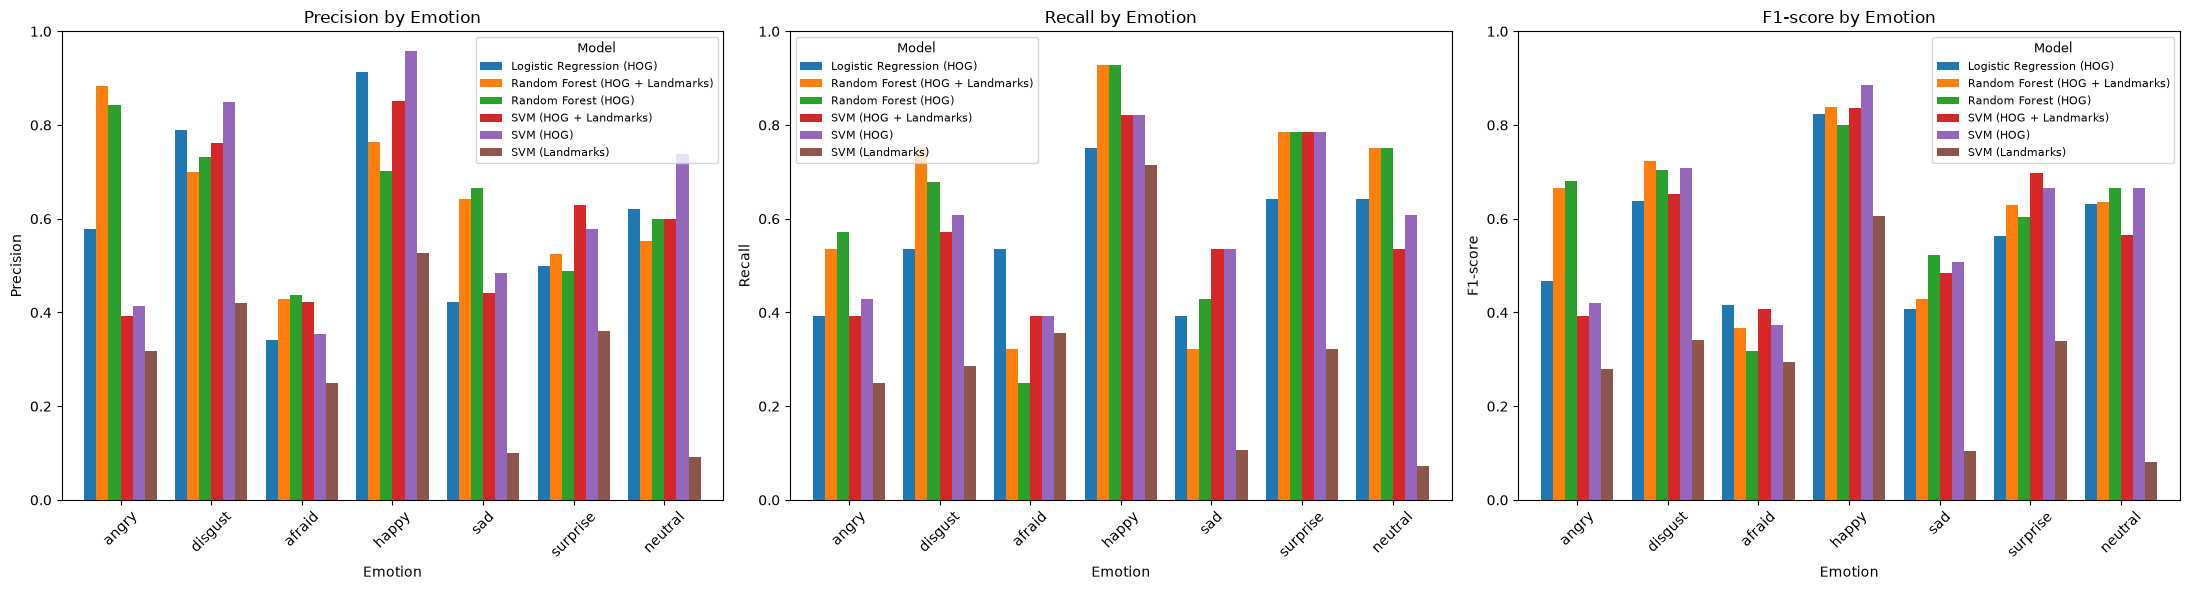

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

# Emotion labels
emotions = ["angry", "disgust", "afraid", "happy", "sad", "surprise", "neutral"]

# Calculate per-emotion metrics for each model
emotion_results = []

for model_name, (model, y_true, y_pred) in models.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=emotions,
        zero_division=0
    )

    for i, emotion in enumerate(emotions):
        emotion_results.append({
            "Model": model_name,
            "Emotion": emotion,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1-score": f1[i]
        })

emotion_df = pd.DataFrame(emotion_results)

# Plot one grouped bar chart for each emotion metric
metrics = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, metric in zip(axes, metrics):
    pivot_df = emotion_df.pivot(
        index="Emotion",
        columns="Model",
        values=metric
    )

    pivot_df = pivot_df.reindex(emotions)
    pivot_df.plot(kind="bar", ax=ax, width=0.8)

    ax.set_title(f"{metric} by Emotion")
    ax.set_xlabel("Emotion")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(
        title="Model",
        fontsize=8,
        title_fontsize=9
    )

plt.tight_layout()
plt.show()

The HOG-based Random Forest model achieves an accuracy of approximately 62.76% and a macro F1-score of approximately 61.34% on the subject-independent KDEF test set.

This configuration achieves the highest accuracy among the evaluated configurations, tied with the Random Forest model using combined HOG and landmark features. The HOG-only configuration has a marginally higher macro F1-score.

The results suggest that HOG features provide a useful representation for facial emotion classification on KDEF. Adding facial landmarks does not improve the reported accuracy and produces a slightly lower macro F1-score in the Random Forest comparison.

Therefore, the HOG-based Random Forest configuration is selected for the cross-dataset generalization experiment.

# Conclusion

The KDEF experiments demonstrate that facial emotion classification performance depends on both the feature representation and the classification algorithm. HOG-based Random Forest classification provides the strongest overall result among the evaluated configurations.

The subject-independent split provides a more realistic assessment of generalization to unseen subjects than a random image-level split. However, evaluation on KDEF alone does not establish whether the learned features transfer to other facial-expression datasets. This motivates the cross-dataset experiment in the `Cross-Dataset Generalization.ipynb`  notebook.